# This notebook applies both the linear and nonlinear methods of regressing out the impact of ENSO from temperature anomalies at each latitude

Cleaned up from de_enso_withsst_fixmlp in cleaned_model_sebm. This code was made with assistance from Claude

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
import scipy.io as io
from scipy.stats import linregress
from scipy.signal import butter, filtfilt



from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

In [2]:
temp_sat=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_trefht_40members_CESM1.nc')
temp_sat=temp_sat.__xarray_dataarray_variable__
temp_sat_anom=temp_sat-temp_sat.mean('ensemble_member')

In [3]:
temp_sst=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_temp_40members_CESM1.nc')
temp_sst=temp_sst.__xarray_dataarray_variable__
temp_sst_anom=temp_sst-temp_sst.mean('ensemble_member')

In [4]:
#https://github.com/ramp-kits/el_nino/blob/master/el_nino_starting_kit.ipynb and https://ncar.github.io/PySpark4Climate/tutorials/Oceanic-Ni%C3%B1o-Index/

#"NOAA's operational definitions of El Niño and La Niña conditions are based upon the Oceanic Niño Index [ONI]. The ONI is defined as the 3-month running means of SST anomalies in the Niño 3.4 region [5N-5S, 120-170W]." (from the second link)
#Define region for el nino index (3.4)
en_lat_bottom = -5
en_lat_top = 5
en_lon_left = -170
en_lon_right = -120

def get_area_mean(tas, lat_bottom, lat_top, lon_left, lon_right):
    # Compute area-weighted mean temperatures in a region
    region = tas.loc[:, lat_bottom:lat_top, lon_left:lon_right]
    
    weights = np.cos(np.deg2rad(region.lat))
    weighted_tas = region.weighted(weights)
    
    return weighted_tas.mean(dim=('lat', 'lon'))

def get_enso_mean(tas):
    # Compute mean temperature in the Nino 3.4 region
    return get_area_mean(tas, en_lat_bottom, en_lat_top, en_lon_left, en_lon_right)

def bandpass_filter_enso(data, low_year=7, high_year=2, fs=12):
    #Applies a Butterworth bandpass filter. Needs longer period (low_year), shorter period (high_year) and sampling frequency (fs)

    enso=get_enso_mean(data)
    # Convert years to frequency (1/T)
    lowcut = 1 / (low_year)
    highcut = 1 / (high_year)
    
    b, a = butter(4, [lowcut, highcut], btype='band',fs=12)
    
    # Apply the filter
    filtered_values = filtfilt(b, a, enso)
    enso_filtered = enso.copy(data=filtered_values)
    return enso_filtered


def stack_bandpassfilterenso(n, temp_sst_anom):
    # Bandpassed ENSO index for the first n members, stacked over (ensemble_member, time)
    sst = temp_sst_anom.isel(ensemble_member=slice(0, n))
    combined = xr.concat(
        [bandpass_filter_enso(sst.isel(ensemble_member=i)) for i in range(n)],
        dim=sst.ensemble_member,  # keep the real member labels
    )
    return combined.stack(stacked_time=('ensemble_member', 'time'))

def stack_temp(n,temp,n0=1):
    combined=temp.sel(ensemble_member=slice(n0, n)).stack(stacked_time=('ensemble_member', 'time')) #stack together time and ensemble dimensions
    return combined

def linregress_ensemble_enso(n,temp_sat_anom,temp_sst_anom,lat):
    result = linregress(stack_bandpassfilterenso(n, temp_sst_anom), stack_temp(n,temp_sat_anom).sel(lat=lat)) #linearly regress bandpassed oni index vs temperature anomalies
    return result.intercept, result.slope

def de_enso(temp_sat_anom,temp_sst_anom,lat,n): 
    #n is the number of ensemble members to fit the statistical model with. but ultimately you detrend each
    intercept,slope=linregress_ensemble_enso(n,temp_sat_anom.mean('lon'),temp_sst_anom,lat) #apply linear regression
    all=[]
    for i in range(40):
        detrend=temp_sat_anom[i,:,:,:].mean('lon').sel(lat=lat)-slope*bandpass_filter_enso(temp_sst_anom[i,:,:,:]) #remove the slope*oni
        all.append(detrend)
    return xr.concat(all, dim='ensemble_member')


def de_enso_vectorized(temp_sat_anom, temp_sst_anom, lat, n):
    # Remove ENSO from SAT at every latitude in lat, fitting the slope on the first n members
    sat = temp_sat_anom.sel(lat=lat).mean('lon')

    # Fit on the first n members, pooled over members and time
    x = stack_bandpassfilterenso(n, temp_sst_anom)
    y = stack_temp(n, sat)
    slope = xr.cov(x, y, dim='stacked_time') / x.var('stacked_time', ddof=1)

    # Remove from every member
    n_all = temp_sst_anom.sizes['ensemble_member']
    enso = stack_bandpassfilterenso(n_all, temp_sst_anom).unstack('stacked_time')
    return sat - slope * enso

Text(0.5, 1.0, 'Oceanic Nino Index')

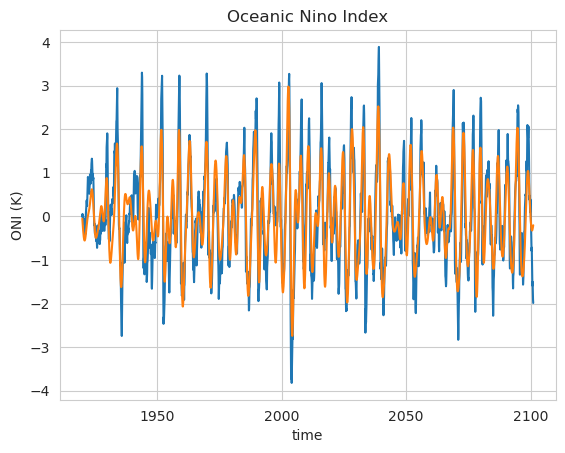

In [6]:
#Plot ONI (both bandpassed and not bandpassed filtered)
get_enso_mean(temp_sst_anom[0,:,:,:]).plot()
bandpass_filter_enso(temp_sst_anom[0,:,:,:]).plot()
plt.ylabel('ONI (K)')
plt.title('Oceanic Nino Index')

In [7]:
a_lin=de_enso_vectorized(temp_sat_anom,temp_sst_anom,temp_sat_anom.lat,20) #fit on 20 members

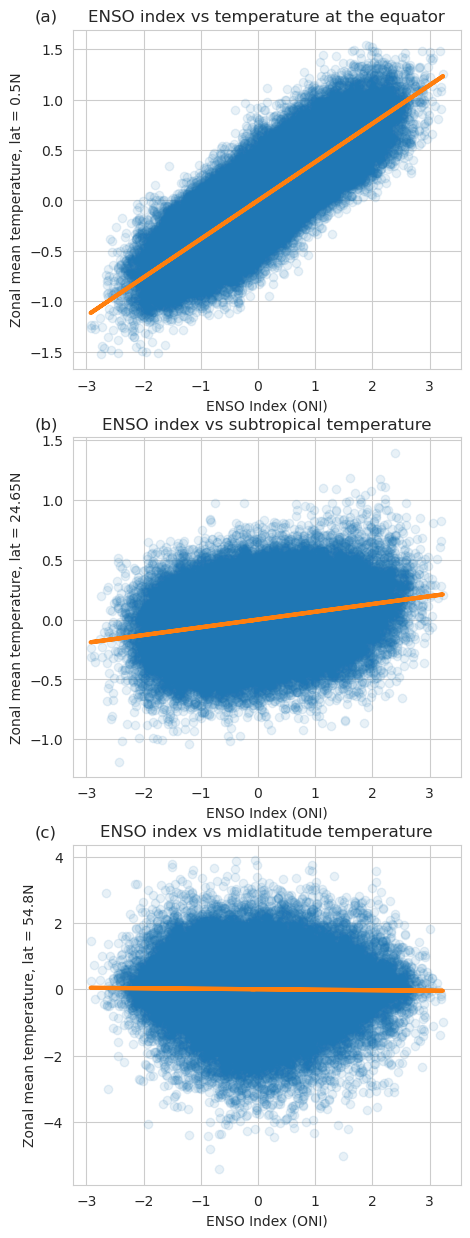

In [8]:
fig,(ax1,ax2,ax3)=plt.subplots(3,1,figsize=(5,15))
ax1.scatter(stack_bandpassfilterenso(40, temp_sst_anom), stack_temp(40,temp_sat_anom.mean('lon'))[90,:],alpha=0.1)
ax1.plot(stack_bandpassfilterenso(40, temp_sst_anom), (stack_temp(40,temp_sat_anom.mean('lon'))[90,:]-stack_temp(40,a_lin)[90,:]),color='tab:orange',linewidth=3)
ax1.set_xlabel('ENSO Index (ONI)')
ax1.set_ylabel('Zonal mean temperature, lat = 0.5N')
ax1.set_title('ENSO index vs temperature at the equator')
ax1.set_title('(a)',loc='left',x=-0.1)


ax2.scatter(stack_bandpassfilterenso(40, temp_sst_anom), stack_temp(40,temp_sat_anom.mean('lon'))[114,:],alpha=0.1)
ax2.set_xlabel('ENSO Index (ONI)')
ax2.plot(stack_bandpassfilterenso(40, temp_sst_anom), (stack_temp(40,temp_sat_anom.mean('lon'))[114,:]-stack_temp(40,a_lin)[114,:]),color='tab:orange',linewidth=3)
ax2.set_ylabel('Zonal mean temperature, lat = 24.65N')
ax2.set_title('ENSO index vs subtropical temperature')
ax2.set_title('(b)',loc='left',x=-0.1)

ax3.scatter(stack_bandpassfilterenso(40, temp_sst_anom), stack_temp(40,temp_sat_anom.mean('lon'))[144,:],alpha=0.1)
ax3.plot(stack_bandpassfilterenso(40, temp_sst_anom), (stack_temp(40,temp_sat_anom.mean('lon'))[144,:]-stack_temp(40,a_lin)[144,:]),color='tab:orange',linewidth=3)
ax3.set_xlabel('ENSO Index (ONI)')
ax3.set_ylabel('Zonal mean temperature, lat = 54.8N')
ax3.set_title('ENSO index vs midlatitude temperature')
ax3.set_title('(c)',loc='left',x=-0.1)

#import matplotlib
#matplotlib.pyplot.savefig('anoms_vs_enso_linfit.png', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)
plt.show()

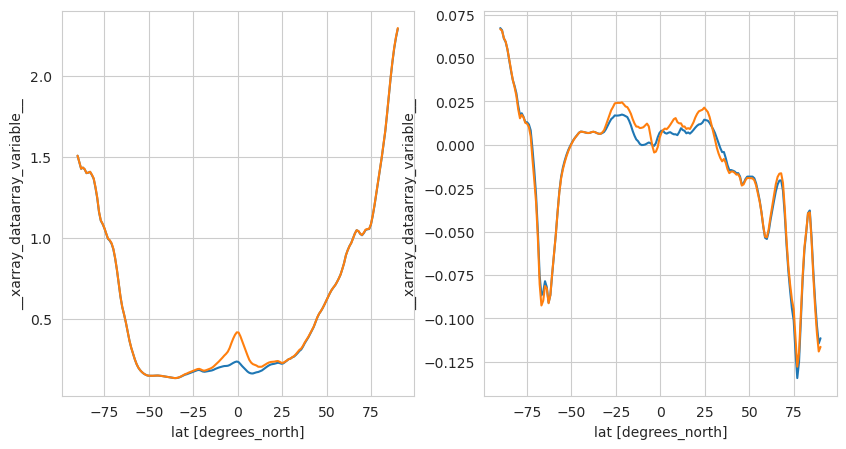

In [9]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,5))

a_lin.std('ensemble_member')[80*12-1:(80+25)*12-1,:].mean('time').plot(ax=ax1)
temp_sat_anom.mean('lon').std('ensemble_member')[80*12-1:(80+25)*12-1,:].mean('time').plot(ax=ax1)

(a_lin.coarsen(time=12).mean().std('ensemble_member')[-30:,:].mean('time')-a_lin.coarsen(time=12).mean().std('ensemble_member')[80-1:(80+25)-1,:].mean('time')).plot(ax=ax2)
(temp_sat_anom.coarsen(time=12).mean().mean('lon').std('ensemble_member')[-30:,:].mean('time')-temp_sat_anom.coarsen(time=12).mean().mean('lon').std('ensemble_member')[80-1:(80+25)-1,:].mean('time')).plot(ax=ax2)

In [10]:
cwd = %pwd
path = cwd + "/data/temp_detrend_linear_regression_enso_norollingmean_sst_oct2026.nc"

a_lin.to_netcdf(path)

# Check if this linear instantaneous removal was enough. Maybe there are substantial lagged relationships?

In [10]:
def calculate_lagged_correlations(data, enso_index, max_lag=12):
    lags = np.arange(0, max_lag + 1)
    corrs = []

    for lag in lags:
        # Shift the index. 
        # Positive lag = ENSO leads Temp
        enso_shifted = enso_index.shift(time=lag)
        
        # Compute correlation across the time dimension
        correlation = xr.corr(data, enso_shifted, dim='time')
        corrs.append(correlation)

    # Combine into a single DataArray
    return xr.concat(corrs, dim='lag').assign_coords(lag=lags)

lags_da = calculate_lagged_correlations(temp_sat_anom[0,:,:,:].mean('lon'), bandpass_filter_enso(temp_sat_anom[0,:,:,:]), max_lag=12)
lags_da_2 = calculate_lagged_correlations(a_lin[0,:,:], bandpass_filter_enso(temp_sat_anom[0,:,:,:]), max_lag=12)

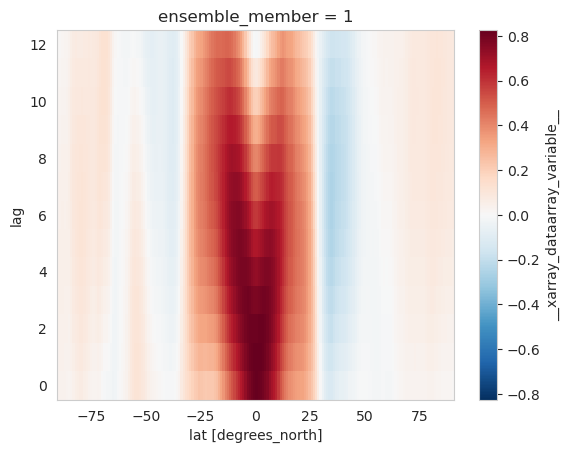

In [11]:
lags_da.plot()

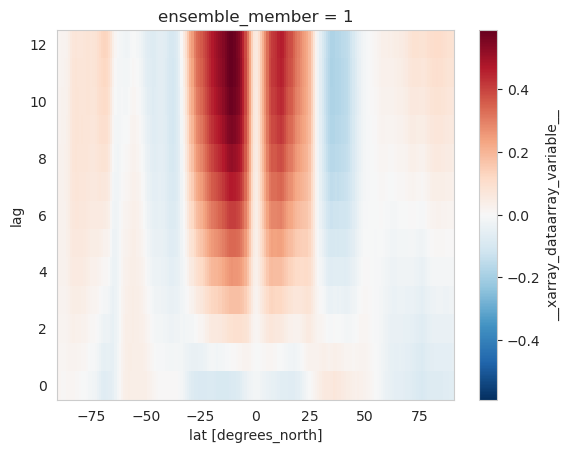

In [12]:
lags_da_2.plot()
#checked those lags in the removed linear with lag 0

In [13]:
def create_lagged_features(enso_series, lags=[0, 2, 4, 6,8,10,12]):
    # If it's xarray, get values
    if hasattr(enso_series, 'values'):
        enso_series = enso_series.values
    
    n_times = len(enso_series)
    X = []
    
    for l in lags:
        # Shift the data. Fill the 'empty' start with 0
        shifted = np.roll(enso_series, l)
        if l > 0:
            shifted[:l] = 0 # Pad
        X.append(shifted)
        
    return np.column_stack(X) # Shape: (n_times, n_lags)


Text(-0.2, 1.0, '(c)')

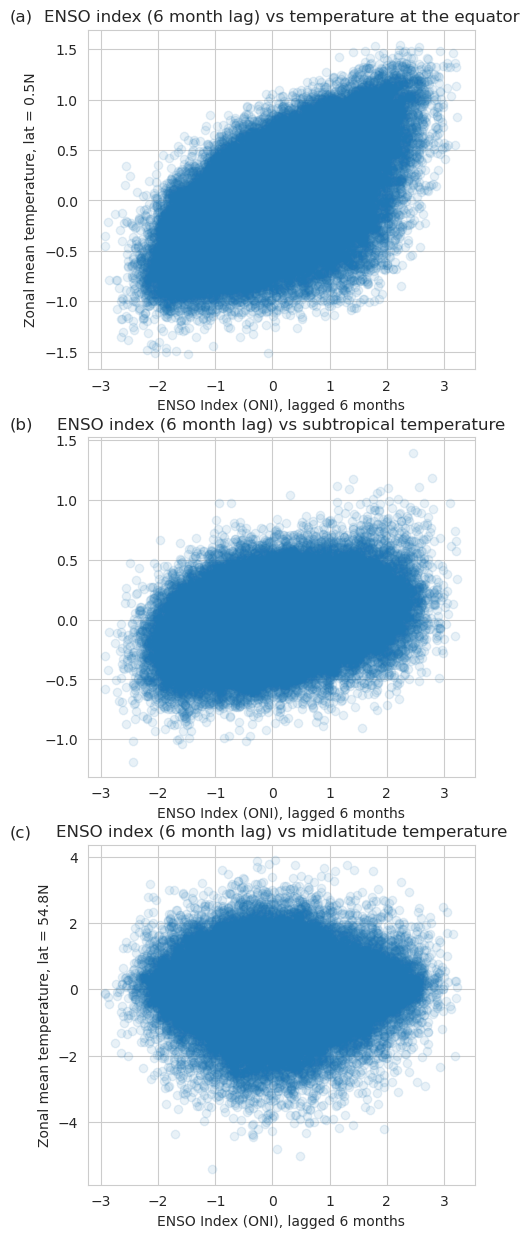

In [14]:
fig,(ax1,ax2,ax3)=plt.subplots(3,1,figsize=(5,15))
ax1.scatter(create_lagged_features(stack_bandpassfilterenso(40, temp_sst_anom))[:,3], stack_temp(40,temp_sat_anom.mean('lon'))[90,:],alpha=0.1)
ax1.set_xlabel('ENSO Index (ONI), lagged 6 months')
ax1.set_ylabel('Zonal mean temperature, lat = 0.5N')
ax1.set_title('ENSO index (6 month lag) vs temperature at the equator')
ax1.set_title('(a)',loc='left',x=-0.2)


ax2.scatter(create_lagged_features(stack_bandpassfilterenso(40, temp_sst_anom))[:,3], stack_temp(40,temp_sat_anom.mean('lon'))[114,:],alpha=0.1)
ax2.set_xlabel('ENSO Index')
ax2.set_xlabel('ENSO Index (ONI), lagged 6 months')
ax2.set_title('ENSO index (6 month lag) vs subtropical temperature')
ax2.set_title('(b)',loc='left',x=-0.2)

ax3.scatter(create_lagged_features(stack_bandpassfilterenso(40, temp_sst_anom))[:,3], stack_temp(40,temp_sat_anom.mean('lon'))[144,:],alpha=0.1)
ax3.set_xlabel('ENSO Index (ONI), lagged 6 months')
ax3.set_ylabel('Zonal mean temperature, lat = 54.8N')
ax3.set_title('ENSO index (6 month lag) vs midlatitude temperature')
ax3.set_title('(c)',loc='left',x=-0.2)
#import matplotlib
#matplotlib.pyplot.savefig('anoms_vs_enso_6monthlag.png', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)
#plt.show()

In [16]:
def de_enso_mlp_vectorized_lag(temp_sat_anom,temp_sst_anom, lat_slice, n_train=40, lags=[0, 2, 4, 6,8,10,12]):
    # Prep training data
    subset = temp_sat_anom.sel(lat=lat_slice).mean('lon')
    
    # We need to collect ENSO features for all training members
    X_train_list = []
    for i in range(n_train):
        enso_idx = bandpass_filter_enso(temp_sst_anom[i]) 
        X_train_list.append(create_lagged_features(enso_idx, lags=lags))
    
    X_raw = np.vstack(X_train_list) # Stacked for all members
    
    # MLP requires scaling
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_raw)
    
    y_train_all = subset.sel(ensemble_member=slice(1, n_train)).stack(st_time=('ensemble_member', 'time'))

    # Loop over latitudes to train models
    models_mean = {}

    print(f"Training Lagged MLPs for {len(lat_slice)} latitudes...")

    for lat_val in lat_slice.values:
        Y = y_train_all.sel(lat=lat_val).values
        
        # Train Model (sees multiple ENSO lags)
        m_mean = MLPRegressor(hidden_layer_sizes=(12, 8), activation='relu', alpha=0.2)
        m_mean.fit(X_scaled, Y)

        
        models_mean[lat_val] = m_mean
       

    # Apply
    all_members_corrected = []
    
    for i in range(len(temp_sat_anom.ensemble_member)):
        member_data = temp_sat_anom[i].mean('lon').sel(lat=lat_slice)
        
        # Create lagged features for THIS specific member
        enso_idx_raw = bandpass_filter_enso(temp_sst_anom[i])
        enso_features = create_lagged_features(enso_idx_raw, lags=lags)
        enso_features_scaled = scaler.transform(enso_features)
        
        corrected_lat_data = []
        for lat_val in lat_slice.values:
            raw_y = member_data.sel(lat=lat_val).values
            
            mu_pred = models_mean[lat_val].predict(enso_features_scaled)
            
            pure_y = ((raw_y - mu_pred))
            corrected_lat_data.append(pure_y)
        
        member_corrected = xr.DataArray(np.array(corrected_lat_data), 
                                        dims=['lat', 'time'], 
                                        coords={'lat': lat_slice, 'time': member_data.time})
        all_members_corrected.append(member_corrected)

    return xr.concat(all_members_corrected, dim='ensemble_member')

In [17]:
a_lagged=de_enso_mlp_vectorized_lag(temp_sat_anom,temp_sst_anom,temp_sat_anom.lat,20)

Training Lagged MLPs for 180 latitudes...


In [18]:
cwd = %pwd
path = cwd + "/data/temp_detrend_mlp_mean_multilag_enso_largerregularization_sst_oct2026.nc"

a_lagged.to_netcdf(path)

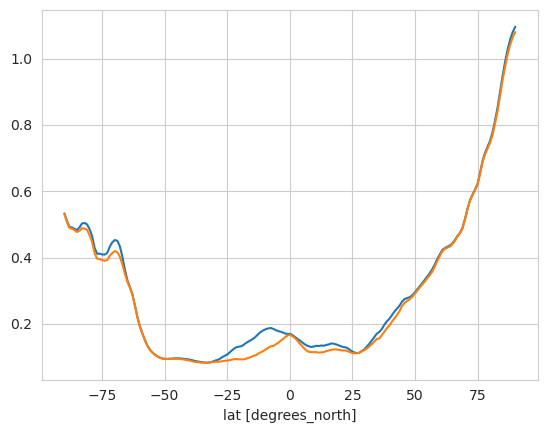

In [19]:
a_lin.coarsen(time=12).mean().std('ensemble_member')[80-1:(80+25)-1,:].mean('time').plot()
a_lagged.coarsen(time=12).mean().std('ensemble_member')[:,80-1:(80+25)-1].mean('time').plot()

In [32]:
lags_da_3 = calculate_lagged_correlations(a_lagged[0,:,:], bandpass_filter_enso(temp_sat_anom[0,:,:,:]), max_lag=12)

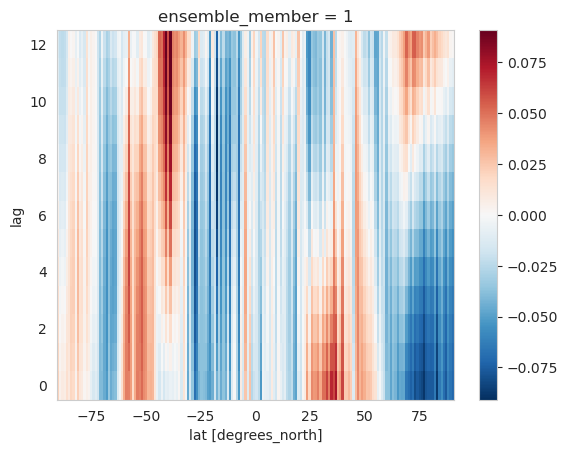

In [33]:
lags_da_3.plot()
#checked those lags in the removed linear with lag 0